# MPRA part 1: from sequencing reads to barcode counts

**Case study: which liver enhancers are active, and how is their activity encoded in their DNA sequence?**

Bravo González-Blas C, Matetovici I, Hillen H, et al. *Single-cell spatial multi-omics and deep learning dissect enhancer-driven gene regulatory networks in liver zonation.* Nature Cell Biology (2024) 26:153–167. https://www.nature.com/articles/s41556-023-01316-4

**Background**

An **enhancer** is a short piece of DNA (a few hundred bp) that increases the transcription of a gene. Enhancers contain binding sites (*motifs*) for transcription factors (TFs). Which enhancers are used differs between cell types, and this is what makes a liver cell a liver cell.

Enhancers are usually predicted from **chromatin accessibility** (ATAC-seq): the DNA of an active enhancer is not wrapped around nucleosomes, so it can be cut by the Tn5 transposase. But accessibility is indirect evidence. To really know whether a piece of DNA can *activate* transcription, you have to test it: clone it in front of a minimal promoter and a reporter gene, put it in a cell and measure how much reporter RNA is made.

A **Massively Parallel Reporter Assay (MPRA)** does this for thousands of sequences at the same time. The trick is to give every tested sequence a **barcode**: a short, unique piece of DNA that ends up in the reporter mRNA. By sequencing the barcodes in the RNA, we count how much mRNA each enhancer produced. By sequencing the barcodes in the plasmid DNA, we know how much of each enhancer was present to start with. The **ratio RNA / DNA** is the activity of the enhancer.

```
        enhancer           promoter   barcode   reporter gene
  ---[ 258 bp of DNA ]---[   SCP1   ]--[BC]----[   Venus   ]---  plasmid (CHEQ-seq)
         ^ the sequence we test        ^ ends up in the mRNA
```

In this study, the authors tested 12,000 sequences (the "12K library") in the **living mouse liver**: the plasmid library was injected in the tail vein of a mouse under high pressure (*hydrodynamic tail vein injection*), which delivers the plasmids to the hepatocytes. After 24 hours the liver was taken out and both the RNA and the plasmid DNA were extracted and sequenced.

**In this notebook** we process the raw sequencing reads of this experiment and build a count table: how many barcode reads do we have for each enhancer, in each sample? In part 2 we use these counts to calculate enhancer activities and interpret them.

**Research questions for this notebook:**

1. How do we link a barcode in a sequencing read to the enhancer it belongs to?
2. How many barcodes does each enhancer have, and why does that matter?
3. How many reads do we end up with per enhancer, and how does that compare to the published count table?

**Note**:

This notebook uses a *bash* kernel. All software (sra-tools, FastQC, MultiQC, cutadapt, fastp, seqkit, pigz) can be installed in a single mamba environment. This environment also contains `bash_kernel`, which allows us to run bash commands in a Jupyter notebook, and the Python packages we need in part 2.

    mamba create -n mpra_teaching -c conda-forge -c bioconda python=3.11 bash_kernel ipykernel \
        sra-tools fastqc multiqc cutadapt fastp seqkit pigz \
        pandas numpy scipy statsmodels matplotlib seaborn pydeseq2 openpyxl homer bedtools

To use this environment in Jupyter we have to register it as a *kernel*. Run the following commands in a terminal (not in this notebook):

```
mamba activate mpra_teaching
KERNEL_DIR=$(jupyter --data-dir)/kernels/bash-mpra
mkdir -p ${KERNEL_DIR}
cat > ${KERNEL_DIR}/kernel.json << EOF
{
  "argv": ["${CONDA_PREFIX}/bin/python", "-m", "bash_kernel", "-f", "{connection_file}"],
  "display_name": "Bash (liver MPRA)",
  "language": "bash",
  "env": {"PATH": "${CONDA_PREFIX}/bin:/usr/local/bin:/usr/bin:/bin", "PS1": "$",
          "PYTHONNOUSERSITE": "1", "CONDA_CHANGEPS1": "false"}
}
EOF
jupyter kernelspec list   # the kernel bash-mpra should be listed
```

The file `kernel.json` tells Jupyter how to start the kernel: using the python of the `mpra_teaching` environment (`${CONDA_PREFIX}` is the location of the active environment). We also add the `bin` folder of the environment to the `PATH`, so the tools (cutadapt, seqkit, ...) are found, even when Jupyter itself is started from another environment. The last two settings keep the output clean: `PYTHONNOUSERSITE` makes sure that packages you installed yourself with `pip install --user` are not mixed in, and `CONDA_CHANGEPS1` stops conda from writing the name of the environment in the prompt of every cell.

Next, (re)start Jupyter and select the kernel "Bash (liver MPRA)" (Kernel > Change Kernel).

Downloading the reads takes ~ 15 minutes and ~ 5 GB of disk space. The whole notebook runs in ~ 30 minutes.

## Step 0: set up working directory

When bash starts it reads your `.bashrc`, which often puts another conda installation (with another python and other versions of our tools) in front of the `PATH`. By activating our environment inside the notebook we make sure that we really use the tools we just installed.

In [1]:
eval "$(conda shell.bash hook)"     # makes the 'conda' command available in this shell
conda activate mpra_teaching
cutadapt --version

5.2


All data will be stored in the folder `data`, next to this notebook.

In [2]:
mkdir -p data
cd data

Note that each code cell of a bash notebook runs in the same shell, so the activated environment and our current folder stay the same throughout the notebook.

## Step 1: get reads

The data is deposited in the Gene Expression Omnibus (GEO) under accession number GSE218472:

https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE218472

This is a *SuperSeries*: it contains several sub-series (single-cell RNA-seq, ATAC-seq, ChIP-seq and the MPRA experiments). The 12K MPRA experiment is sub-series [GSE218471](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE218471).

The 12K library was cloned in two versions of the reporter plasmid:

- **5' library**: the barcode is in the 5' UTR of the reporter gene (between the promoter and the Venus gene)
- **3' library**: the barcode is in the 3' UTR (between Venus and the poly(A) signal)

We will analyse the **5' library in the mouse liver**, because for this version the enhancer-barcode assignment (see Step 4) was done with Illumina sequencing, which is easier to handle than the Nanopore sequencing used for the 3' libraries.

The samples we need:

| GEO sample | SRA run | Description | Our sample name |
|---|---|---|---|
| GSM6745700 | SRR22363327 | enhancer-barcode assignment, run 1 | assignment_run1 |
| GSM6745700 | SRR22363328 | enhancer-barcode assignment, run 2 | assignment_run2 |
| GSM6745692 | SRR22363336 | mouse 1, replicate 1, cDNA | mouse1_rep1_cDNA |
| GSM6745693 | SRR22363335 | mouse 1, replicate 1, plasmid | mouse1_rep1_plasmid |
| GSM6745694 | SRR22363334 | mouse 2, replicate 1, cDNA | mouse2_rep1_cDNA |
| GSM6745695 | SRR22363333 | mouse 2, replicate 1, plasmid | mouse2_rep1_plasmid |
| GSM6745696 | SRR22363332 | mouse 1, replicate 2, cDNA | mouse1_rep2_cDNA |
| GSM6745697 | SRR22363331 | mouse 1, replicate 2, plasmid | mouse1_rep2_plasmid |
| GSM6745698 | SRR22363330 | mouse 2, replicate 2, cDNA | mouse2_rep2_cDNA |
| GSM6745699 | SRR22363329 | mouse 2, replicate 2, plasmid | mouse2_rep2_plasmid |

"Replicate" here means a second, independent injection of the same library in a mouse (the two mice of replicate 1 are not the same animals as those of replicate 2). For each mouse, the **cDNA** (made from the reporter mRNA) and the **plasmid** DNA were sequenced: these form a pair.

We store the accession numbers and the names we want to use in a small text file. Note that we separate the two columns by **spaces**, not by a tab: a literal tab character in a cell of a bash notebook is interpreted by the shell as a request for auto-completion and gets lost. `while read` splits on any whitespace, so this works just as well.

In [3]:
cat > samples.txt << EOF
SRR22363327 assignment_run1
SRR22363328 assignment_run2
SRR22363336 mouse1_rep1_cDNA
SRR22363335 mouse1_rep1_plasmid
SRR22363334 mouse2_rep1_cDNA
SRR22363333 mouse2_rep1_plasmid
SRR22363332 mouse1_rep2_cDNA
SRR22363331 mouse1_rep2_plasmid
SRR22363330 mouse2_rep2_cDNA
SRR22363329 mouse2_rep2_plasmid
EOF
cat samples.txt

SRR22363327 assignment_run1


SRR22363328 assignment_run2


SRR22363336 mouse1_rep1_cDNA


SRR22363335 mouse1_rep1_plasmid


SRR22363334 mouse2_rep1_cDNA


SRR22363333 mouse2_rep1_plasmid


SRR22363332 mouse1_rep2_cDNA


SRR22363331 mouse1_rep2_plasmid


SRR22363330 mouse2_rep2_cDNA


SRR22363329 mouse2_rep2_plasmid


All libraries are **paired end**, sequenced on a NextSeq 2000 with 2 x 51 bp reads.

There are two ways to download reads from a public archive:

1. **SRA (NCBI)** with `prefetch` + `fasterq-dump` (the `sra-tools`), as in the RNA-seq practical. This always works, but the download can be slow.
2. **ENA (EMBL-EBI)**, the European mirror of the same data. ENA stores the files directly as `fastq.gz`, so we can download them with `wget`. This is usually much faster.

The ENA url of a run is built from its accession number:

```
https://ftp.sra.ebi.ac.uk/vol1/fastq/SRR223/027/SRR22363327/SRR22363327_1.fastq.gz
                                     ^^^^^^ ^^^ ^^^^^^^^^^^  ^^^^^^^^^^^
                                     first 6  last 2 digits   full accession, read 1 or 2
                                     characters (with a 0 in front)
```

Let's first test the download on a few reads using `fastq-dump` (SRA), to see what the data looks like.

In [4]:
mkdir -p fastq_files_test
# -X 10000: only download the first 10000 reads (for testing, never do this for real data)
# --split-files: write read 1 and read 2 to separate files
fastq-dump SRR22363327 --split-files --outdir fastq_files_test -X 10000
ls -lhgG fastq_files_test

Read 10000 spots for SRR22363327


Written 10000 spots for SRR22363327


total 1.0K


-rw-rw----+ 1 2.3M Oct 28 20:36 SRR22363327_1.fastq


-rw-rw----+ 1 2.3M Oct 28 20:36 SRR22363327_2.fastq


In [5]:
head -n 4 fastq_files_test/SRR22363327_1.fastq
echo "---"
head -n 4 fastq_files_test/SRR22363327_2.fastq

@SRR22363327.1 A00311:301:HYFKMDRXX:1:2101:3405:1031 length=49


TNCCCAGTGCAAGTGCAGGCCTGTCAAGAACCCGGAGCACTAGCTCACA


+SRR22363327.1 A00311:301:HYFKMDRXX:1:2101:3405:1031 length=49


F#FFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF


---


@SRR22363327.1 A00311:301:HYFKMDRXX:1:2101:3405:1031 length=48


AATTAATTCGGGCCCCGGTCCAATTTGCAAATTAACCTGATCGGCGCG


+SRR22363327.1 A00311:301:HYFKMDRXX:1:2101:3405:1031 length=48


F:FFFFFFFFFFFFFFFFFFFFFFFFFF:F:FFFFFFFFFFFFFFFFF


As a reminder, each read takes 4 lines in a fastq file: the identifier (starting with `@`), the sequence, a `+` line and the quality of each base encoded as ASCII characters. Read 1 and read 2 of the same fragment have the same identifier.

Now let's download all reads from ENA. This takes ~ 15 minutes (~ 5 GB).

In [6]:
mkdir -p fastq_files
while read SRR NAME
do
    for R in 1 2
    do
        OUT=fastq_files/${NAME}_R${R}.fastq.gz
        if [ -f ${OUT} ]; then continue; fi            # skip files we already have
        URL=https://ftp.sra.ebi.ac.uk/vol1/fastq/${SRR:0:6}/0${SRR: -2}/${SRR}/${SRR}_${R}.fastq.gz
        echo "Downloading ${NAME} read ${R}"
        wget -q -O ${OUT}.tmp ${URL} && mv ${OUT}.tmp ${OUT}   # only rename when the download succeeded
    done
done < samples.txt
ls -lhgG fastq_files

total 4.7G


-rw-rw----+ 1 151M Oct 28 18:43 assignment_run1_R1.fastq.gz


-rw-rw----+ 1 131M Oct 28 18:43 assignment_run1_R2.fastq.gz


-rw-rw----+ 1 512M Sep  9  2023 assignment_run2_R1.fastq.gz


-rw-rw----+ 1 436M Sep  9  2023 assignment_run2_R2.fastq.gz


...

-rw-rw----+ 1 165M Sep  9  2023 mouse2_rep1_plasmid_R2.fastq.gz


-rw-rw----+ 1 372M Sep  9  2023 mouse2_rep2_cDNA_R1.fastq.gz


-rw-rw----+ 1 374M Sep  9  2023 mouse2_rep2_cDNA_R2.fastq.gz


-rw-rw----+ 1 344M Sep  9  2023 mouse2_rep2_plasmid_R1.fastq.gz


-rw-rw----+ 1 339M Sep  9  2023 mouse2_rep2_plasmid_R2.fastq.gz


Let's count the reads in one file. Remember: number of reads = number of lines / 4.

In [7]:
echo $(zcat fastq_files/mouse1_rep1_cDNA_R1.fastq.gz | wc -l)/4 | bc

2695054


**Question**: Compare this number with the number of spots reported on SRA for SRR22363336. Should read 2 have the same number of reads?

## Step 2: quality control with FastQC

As always, the first step after receiving sequencing data is to check the quality. [FastQC](http://www.bioinformatics.babraham.ac.uk/projects/fastqc/) produces a report per fastq file.

    fastqc fastqfile --outdir outputdir

This takes ~ 10 minutes for all 20 files.

In [8]:
mkdir -p fastqc
fastqc -t 10 --outdir fastqc fastq_files/*.fastq.gz 2>&1 | grep -v "^Approx"

Started analysis of assignment_run1_R1.fastq.gz


Started analysis of assignment_run1_R2.fastq.gz


Analysis complete for assignment_run1_R1.fastq.gz


Analysis complete for assignment_run1_R2.fastq.gz


Started analysis of assignment_run2_R1.fastq.gz


...

Analysis complete for mouse2_rep2_cDNA_R2.fastq.gz


Started analysis of mouse2_rep2_plasmid_R2.fastq.gz


Analysis complete for mouse2_rep2_plasmid_R1.fastq.gz


Analysis complete for mouse2_rep2_plasmid_R2.fastq.gz


[WARNING] Above 4 threads you should use a multiple of 4 (so 4, 8, 12 etc) for maximum benefit


In [9]:
multiqc -f -o multiqc_fastqc fastqc 2> /dev/null
ls multiqc_fastqc

multiqc_data  multiqc_report.html


Open `multiqc_fastqc/multiqc_report.html` in your browser. MultiQC also writes the summary statistics to a text file:

In [10]:
cut -f 1,5,10,11,12 multiqc_fastqc/multiqc_data/multiqc_fastqc.txt | column -t -s $'\t'

Sample                  Total Sequences  %GC   total_deduplicated_percentage  avg_sequence_length


assignment_run1_R1      5003991.0        55.0  7.760593132883126              49.0


assignment_run1_R2      5003991.0        56.0  81.37195109312354              48.0


assignment_run2_R1      31343861.0       55.0  9.167727612793954              49.0


assignment_run2_R2      31343861.0       56.0  58.21454367665103              48.0


...

mouse2_rep1_plasmid_R2  10433610.0       57.0  10.673813225661629             50.0


mouse2_rep2_cDNA_R1     28599819.0       62.0  5.461540257035035              50.0


mouse2_rep2_cDNA_R2     28599819.0       58.0  7.3030991970746655             50.0


mouse2_rep2_plasmid_R1  37458590.0       61.0  2.004314935344759              50.0


mouse2_rep2_plasmid_R2  37458590.0       61.0  2.7683005870990445             50.0


Two things stand out compared to an RNA-seq experiment:

- The **percentage of duplicates is very high** (the `total_deduplicated_percentage` is low). This is expected and even wanted here: we are sequencing a short barcode region that is the same in millions of molecules. A low duplication rate would mean we did not sequence deep enough.
- The **GC content** is unusual, because most of each read is the constant plasmid sequence around the barcode.

Let's look at the per base sequence quality and the per base sequence content of one of the assignment samples.

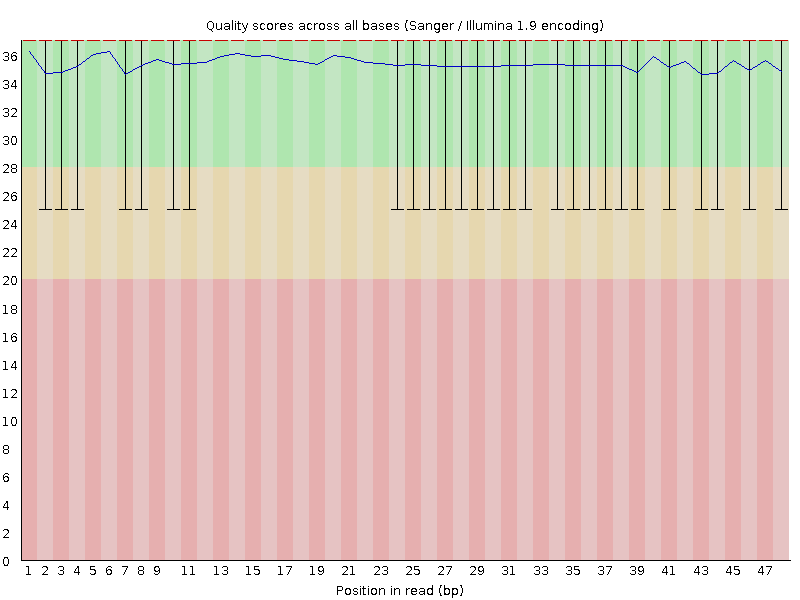

In [11]:
unzip -o -q fastqc/assignment_run1_R2_fastqc.zip -d fastqc
display < fastqc/assignment_run1_R2_fastqc/Images/per_base_quality.png

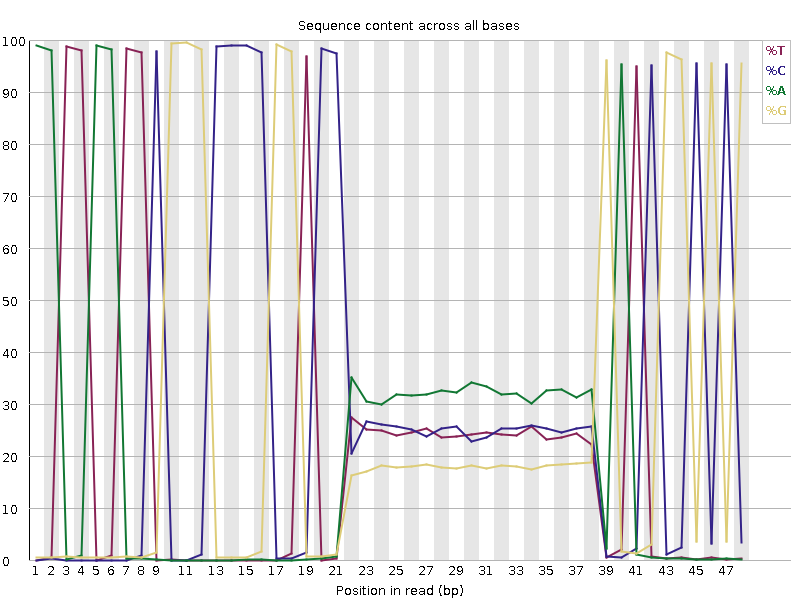

In [12]:
display < fastqc/assignment_run1_R2_fastqc/Images/per_base_sequence_content.png

The quality is good (nearly all bases above Q30). The per base sequence content is very striking: for most positions, one base is present in ~ 100% of the reads (flat coloured lines at 0 and 100%), and in the middle there is a region where all four bases occur. These constant parts are the **plasmid sequence**, and the variable part in the middle is the **barcode**. FastQC flags this as a failure, but for this kind of library it is exactly what we expect.

**Question**: Look at the same plot for `assignment_run1_R1`. Where is the variable region, and how long is it?

## Step 3: the structure of the reads

Before we can count anything, we need to understand what is in each read. There are **two different barcodes** in this experiment:

1. The **oligo barcode** (12 bp): this was part of the synthesized oligonucleotide, right next to the enhancer. Every enhancer has its own, known oligo barcode. It is a *name tag* that identifies the enhancer. We know the list of 12,000 oligo barcodes from the supplementary tables of the paper.
2. The **plasmid barcode** (17 bp): a *random* barcode that was introduced during the cloning, in the 5' UTR of the reporter. Each individual plasmid molecule got a random barcode, so one enhancer ends up with many different plasmid barcodes. This is the barcode that ends up in the mRNA, so this is the barcode we count.

Why two barcodes? The oligo barcode is next to the enhancer and far from the promoter, so it does not end up in the (short) reporter mRNA. The plasmid barcode is in the mRNA, but because it is random we do not know in advance which plasmid barcode belongs to which enhancer. That is what the **assignment experiment** is for: sequence the plasmid library in a way that reads both barcodes from the same molecule, and build a dictionary.

```
assignment experiment (read both barcodes of the same plasmid):

   read 1:  ...TGTCCCCAGTGCAAGTGCAG [ 12 bp oligo barcode ] ...     -> which enhancer?
   read 2:  ...AATTAATTCGGGCCCCGGTCC [ 17 bp plasmid barcode ] GATCGGCGCGCCTGCTCG...

cDNA / plasmid samples (only the plasmid barcode is sequenced):

   read 2:  ...AATTAATTCGGGCCCCGGTCC [ 17 bp plasmid barcode ] GATCGGCGCGCCTGCTCG...
```

Let's look at the first reads of the assignment sample to see these constant sequences.

In [13]:
zcat fastq_files/assignment_run1_R1.fastq.gz | head -n 8 | awk 'NR % 4 == 2'
echo "---"
zcat fastq_files/assignment_run1_R2.fastq.gz | head -n 8 | awk 'NR % 4 == 2'

TNCCCAGTGCAAGTGCAGGCCTGTCAAGAACCCGGAGCACTAGCTCACA


TNCCCAGTGCAAGTGCAGTTAGATAGTCGGCTGTCCTTGGGCTGAAATT


---


AATTAATTCGGGCCCCGGTCCAATTTGCAAATTAACCTGATCGGCGCG


AATTAATTCGGGCCCCGGTCCTGTAATACATACCAGTAGATCGGCGCG


In read 1 you can recognize `CCAGTGCAAGTGCAG` (the adaptor that was added to every oligo) followed by 12 variable bases. In read 2, `AATTAATTCGGGCCCCGGTCC` is followed by 17 variable bases and then `GATCGGCGCG...`.

### The list of designed oligo barcodes

Supplementary Table 2 of the paper lists, for each of the 12,000 tested sequences, its oligo barcode. We download the Excel file and write the two columns we need to a simple tab separated file. (We use a small Python snippet because the table is an Excel file; `python` here is the python of our environment.)

In [14]:
mkdir -p geo
wget -nc -q -P geo "https://static-content.springer.com/esm/art%3A10.1038%2Fs41556-023-01316-4/MediaObjects/41556_2023_1316_MOESM4_ESM.xlsx"
python -c "
import pandas as pd
tbl = pd.read_excel('geo/41556_2023_1316_MOESM4_ESM.xlsx', sheet_name='Supplementary Table 2', header=1)
tbl[['Barcode', 'EnhancerID']].to_csv('oligo_barcodes.tsv', sep='\t', header=False, index=False)
print(tbl.shape[0], 'sequences,', tbl['Barcode'].nunique(), 'unique oligo barcodes of', tbl['Barcode'].str.len().unique(), 'bp')
"
head -n 3 oligo_barcodes.tsv

12000 sequences, 12000 unique oligo barcodes of [12] bp


CACGTCTGTATT	chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287


TATTACAGGACC	chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458


AGCTCGTATGTT	chr1:102561276-102561534__mm10__AGCTCGTATGTT__chr1:102561214-102561715


Each sequence has its own unique 12 bp oligo barcode. The name of a sequence (`EnhancerID`) consists of the cloned region, the genome (`mm10` for mouse regions, `hg19` for human positive controls, `shuffle` for the negative controls), the oligo barcode and the original ATAC-seq peak.

## Step 4: build the enhancer-barcode assignment

Now we build the dictionary that links each **plasmid barcode** to an **enhancer**, using the two assignment runs.

### 4a. Cut out the barcodes with cutadapt

[cutadapt](https://cutadapt.readthedocs.io/) finds an adaptor sequence in a read and removes it. We use it to keep only the barcodes:

- For **read 1**: `-g TGTCCCCAGTGCAAGTGCAG` removes everything up to and including this sequence (a *5' adaptor*). What is left starts with the 12 bp oligo barcode (followed by the enhancer).
- For **read 2**: `-G ADAPTER1...ADAPTER2` is a *linked adaptor*: cutadapt removes everything before `AATTAATTCGGGCCCCGGTCC` and everything from `GATCGGCGCGCCTGCTCG` onwards, keeping only what is in between: the plasmid barcode. (Lowercase options apply to read 1, uppercase to read 2.)

Other options:

- `--discard-untrimmed`: throw away read pairs in which the adaptor was not found (these are not proper library molecules)
- `-m 12:17 -M 1000:17`: the minimum and maximum length of read 1 and read 2 after trimming. The plasmid barcode must be exactly 17 bp, so we require `-m 17` and `-M 17` for read 2. Read 1 is longer because the enhancer follows the oligo barcode.
- `--pair-filter=any`: if one read of the pair fails a filter, remove the whole pair
- `-j 8`: use 8 threads

This takes ~ 2 minutes.

In [15]:
mkdir -p barcodes
for RUN in assignment_run1 assignment_run2
do
    echo "=== ${RUN}"
    cutadapt -j 8 \
        -g TGTCCCCAGTGCAAGTGCAG \
        -G AATTAATTCGGGCCCCGGTCC...GATCGGCGCGCCTGCTCG \
        --discard-untrimmed --pair-filter=any \
        -m 12:17 -M 1000:17 \
        -o barcodes/${RUN}_R1.trimmed.fq.gz \
        -p barcodes/${RUN}_R2.trimmed.fq.gz \
        fastq_files/${RUN}_R1.fastq.gz fastq_files/${RUN}_R2.fastq.gz \
        > barcodes/${RUN}.cutadapt.log 2>&1
    grep -E "Total read pairs|Read 1 with adapter|Read 2 with adapter|Pairs written" barcodes/${RUN}.cutadapt.log
done

=== assignment_run1


Total read pairs processed:          5,003,991


  Read 1 with adapter:               4,991,634 (99.8%)


  Read 2 with adapter:               4,857,483 (97.1%)


Pairs written (passing filters):     4,786,044 (95.6%)


=== assignment_run2


Total read pairs processed:         31,343,861


  Read 1 with adapter:              30,235,919 (96.5%)


  Read 2 with adapter:              28,471,003 (90.8%)


Pairs written (passing filters):    28,031,447 (89.4%)


The adaptor is found in 97 - 100% of the read 1's and in 91 - 97% of the read 2's, and 89 - 96% of the pairs survive both filters: the libraries are clean.

Read 1 still contains the beginning of the enhancer after the oligo barcode. We only need the barcode, so we cut read 1 down to its first 12 bases with `seqkit subseq`.

In [16]:
for RUN in assignment_run1 assignment_run2
do
    seqkit subseq -r 1:12 barcodes/${RUN}_R1.trimmed.fq.gz -o barcodes/${RUN}_R1.bc.fq.gz
done
zcat barcodes/assignment_run1_R1.bc.fq.gz | head -n 4

@SRR22363327.1 A00311:301:HYFKMDRXX:1:2101:3405:1031 length=49


GCCTGTCAAGAA


+


FFFFFFFFFFFF


### 4b. Remove low quality reads

A sequencing error in a barcode creates a barcode that does not exist, or - worse - one that belongs to another enhancer. We therefore remove read pairs of low quality with [fastp](https://github.com/OpenGene/fastp):

- `-q 30`: a base is "qualified" if its quality is at least 30 (1 error in 1000). By default, fastp discards a read if more than 40% of its bases are unqualified.
- `-A -G -L`: switch off adaptor trimming, polyG trimming and length filtering (we already did the trimming ourselves)

In [17]:
for RUN in assignment_run1 assignment_run2
do
    echo "=== ${RUN}"
    fastp -i barcodes/${RUN}_R1.bc.fq.gz -I barcodes/${RUN}_R2.trimmed.fq.gz \
          -o barcodes/${RUN}_R1.filtered.fq.gz -O barcodes/${RUN}_R2.filtered.fq.gz \
          -q 30 -A -G -L -w 8 \
          -j barcodes/${RUN}.fastp.json -h barcodes/${RUN}.fastp.html \
          > barcodes/${RUN}.fastp.log 2>&1
    grep -A3 "Filtering result" barcodes/${RUN}.fastp.log
done

=== assignment_run1


Filtering result:


reads passed filter: 9054162


reads failed due to low quality: 517926


reads failed due to too many N: 0


=== assignment_run2


Filtering result:


reads passed filter: 56039088


reads failed due to low quality: 23806


reads failed due to too many N: 0


### 4c. Pair up the two barcodes

Both files are still in the same order: the n-th read of file 1 belongs to the n-th read of file 2. We extract only the sequences (`seqkit seq -s`) and paste them next to each other.

One extra step: the plasmid barcode is sequenced from the other strand in read 2 than in the mRNA, so we take the **reverse complement** of read 2 (`seqkit seq -r -p`, `-r` = reverse, `-p` = complement). This way our barcodes are in the same orientation everywhere.

In [18]:
for RUN in assignment_run1 assignment_run2
do
    paste <(seqkit seq -s barcodes/${RUN}_R1.filtered.fq.gz 2> /dev/null) \
          <(seqkit seq -s -r -p -t DNA barcodes/${RUN}_R2.filtered.fq.gz 2> /dev/null) \
          > barcodes/${RUN}.pairs.txt
done
head -n 3 barcodes/assignment_run1.pairs.txt
wc -l barcodes/*.pairs.txt

GCCTGTCAAGAA	AGGTTAATTTGCAAATT


TTAGATAGTCGG	TACTGGTATGTATTACA


ACGCGAAGGTAC	GCAAAATGGTGCGGCAA


   4527081 barcodes/assignment_run1.pairs.txt


  28019544 barcodes/assignment_run2.pairs.txt


  32546625 total


Each line is one read pair: the oligo barcode (enhancer) and the plasmid barcode that were on the same molecule. Many molecules are sequenced several times, so let's count how often each combination occurs. `sort | uniq -c` is the classic way to count unique lines; with `awk` we put the count in the last column.

In [19]:
cat barcodes/assignment_run1.pairs.txt barcodes/assignment_run2.pairs.txt \
    | sort -S 8G --parallel 8 | uniq -c \
    | awk -v OFS='\t' '{print $2, $3, $1}' \
    > barcodes/all_pairs.tsv
head -n 3 barcodes/all_pairs.tsv
wc -l barcodes/all_pairs.tsv

AAAAAAAAAAAA	AATGATGTGTACGGTGT	4


AAAAAAAAAAAA	AGACAGGAGCTCCTCGA	1


AAAAAAAAAAAA	AGCGCCGCGGATGCGGG	6


24455188 barcodes/all_pairs.tsv


### 4d. Keep the barcodes that are unambiguous

In an ideal library, each plasmid barcode is attached to exactly one enhancer. In practice some plasmid barcodes are found with several enhancers, because:

- the same random barcode was used twice by chance (there are 4^17 = 17 billion possible 17-mers, but the library has millions of molecules),
- recombination during the cloning or PCR (a "chimeric" molecule),
- sequencing errors in the oligo barcode.

Such ambiguous barcodes cannot be interpreted, so we throw them away. `uniq -u` prints only the lines that occur exactly once, which is exactly what we need: plasmid barcodes that are seen with only one enhancer.

In [20]:
cut -f 2 barcodes/all_pairs.tsv | sort -S 8G --parallel 8 | uniq -u > barcodes/unambiguous_bc.txt
echo "plasmid barcodes in total:     $(cut -f2 barcodes/all_pairs.tsv | sort -u | wc -l)"
echo "assigned to exactly one enhancer: $(wc -l < barcodes/unambiguous_bc.txt)"

plasmid barcodes in total:     14465456


assigned to exactly one enhancer: 8774196


About 60% of the plasmid barcodes are linked to a single enhancer. That may seem low, but most of the discarded ones are barcodes seen in only one or two reads, in which a single sequencing error in the oligo barcode is enough to make them look ambiguous. The authors report 78.3% with their slightly different filtering.

Now we `join` these three pieces of information:

1. the unambiguous plasmid barcodes,
2. the pairs (plasmid barcode - oligo barcode - number of reads),
3. the designed oligo barcodes (oligo barcode - enhancer name).

`join` works like a database join (as `merge` in pandas or R), but it requires both files to be **sorted on the key column**, so we sort first. The `-o` option selects which columns we want in the output.

In [21]:
# 1 + 2: keep only the pairs with an unambiguous plasmid barcode
sort -k2,2 -S 8G --parallel 8 barcodes/all_pairs.tsv > barcodes/all_pairs.sorted.tsv
join -t $'\t' -1 1 -2 2 -o 2.1,2.2,2.3 \
     barcodes/unambiguous_bc.txt barcodes/all_pairs.sorted.tsv \
     | sort -k1,1 -S 8G --parallel 8 > barcodes/unambiguous_pairs.tsv

# + 3: translate the oligo barcode into the name of the enhancer
sort -k1,1 oligo_barcodes.tsv > oligo_barcodes.sorted.tsv
join -t $'\t' -o 2.2,1.2,2.3 \
     oligo_barcodes.sorted.tsv barcodes/unambiguous_pairs.tsv \
     > barcodes/barcode_to_enhancer.tsv

head -n 3 barcodes/barcode_to_enhancer.tsv
wc -l barcodes/barcode_to_enhancer.tsv

AAAACCGGAAGATTGGT	chr18:38670870-38671128__mm10__AACAACAACACC__chr18:38670726-38671227	1


AAAACCGGACGATTGGT	chr18:38670870-38671128__mm10__AACAACAACACC__chr18:38670726-38671227	1


AAAACCTCTTGTTTCAT	chr18:38670870-38671128__mm10__AACAACAACACC__chr18:38670726-38671227	1


7474651 barcodes/barcode_to_enhancer.tsv


This is our dictionary: 7.5 million plasmid barcodes (column 1), each linked to one enhancer (column 2), with the number of reads that supported the link (column 3).

**Question**: We lost some barcodes in the last join. Which ones, and why?

### 4e. How many barcodes does each enhancer have?

This is one of the most important quality measures of an MPRA library. Having many barcodes per enhancer is like having many technical replicates: the activity of an enhancer is measured as the sum over all its barcodes, so random fluctuations of individual barcodes average out.

In [22]:
cut -f 2 barcodes/barcode_to_enhancer.tsv | sort -S 8G --parallel 8 | uniq -c \
    | awk -v OFS='\t' '{print $2, $1}' > barcodes/barcodes_per_enhancer.tsv

echo "enhancers with at least one barcode: $(wc -l < barcodes/barcodes_per_enhancer.tsv) (of 12000)"
awk '{print $2}' barcodes/barcodes_per_enhancer.tsv | sort -n | awk '
    { v[NR] = $1; sum += $1 }
    END { printf "min %d | 25%% %d | median %d | 75%% %d | max %d | mean %.0f\n",
                 v[1], v[int(NR*0.25)], v[int(NR*0.5)], v[int(NR*0.75)], v[NR], sum/NR }'

enhancers with at least one barcode: 11866 (of 12000)


min 1 | 25% 81 | median 280 | 75% 764 | max 17970 | mean 630


The median enhancer has several hundred barcodes, which is plenty. But some enhancers have very few: their activity will be measured much less precisely.

**Question**: 134 of the 12,000 designed sequences ended up without a single barcode. Give two possible explanations.

A picture says more than these numbers. We make two plots with python (matplotlib) and show them in the notebook. The first shows how many barcodes each enhancer has; the second is a *Lorenz curve*: it shows which fraction of all barcodes belongs to the x% least represented enhancers. A perfectly uniform library would follow the diagonal.

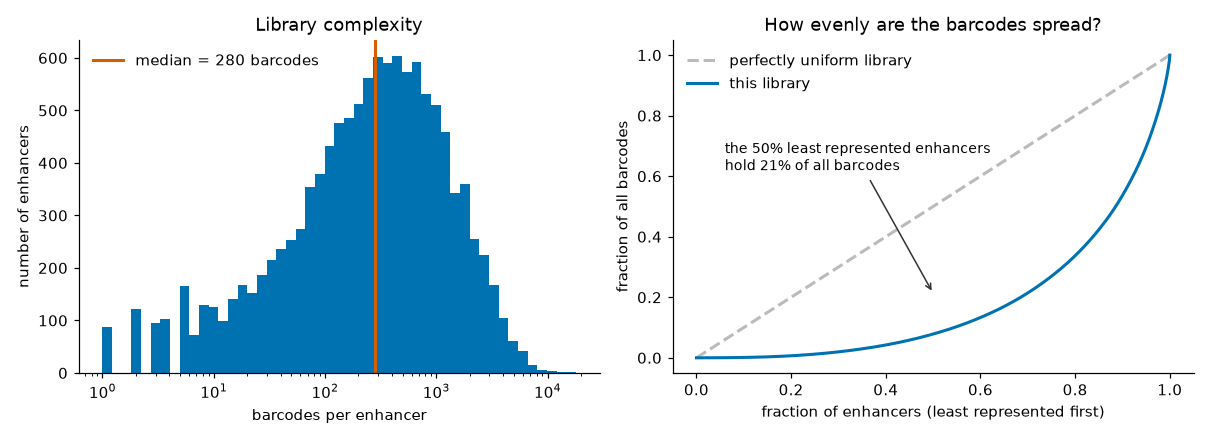

In [23]:
python - << 'EOF'
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

BLUE, ORANGE, GREY = "#0072B2", "#D55E00", "#BBBBBB"
nbc = pd.read_csv("barcodes/barcodes_per_enhancer.tsv", sep="\t", header=None,
                  names=["enhancer", "n"])["n"].sort_values()

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

axs[0].hist(nbc, bins=np.logspace(0, np.log10(nbc.max()), 50), color=BLUE)
axs[0].axvline(nbc.median(), color=ORANGE, lw=2,
               label=f"median = {int(nbc.median())} barcodes")
axs[0].set_xscale("log")
axs[0].set_xlabel("barcodes per enhancer")
axs[0].set_ylabel("number of enhancers")
axs[0].set_title("Library complexity")
axs[0].legend(frameon=False)

share = np.cumsum(nbc) / nbc.sum()
frac = np.arange(1, len(nbc) + 1) / len(nbc)
axs[1].plot([0, 1], [0, 1], color=GREY, lw=2, ls="--", label="perfectly uniform library")
axs[1].plot(frac, share, color=BLUE, lw=2, label="this library")
half = share[np.searchsorted(frac, 0.5)]
axs[1].annotate(f"the 50% least represented enhancers\nhold {half * 100:.0f}% of all barcodes",
                xy=(0.5, half), xytext=(0.06, 0.62), fontsize=9,
                arrowprops=dict(arrowstyle="->", color="#333333"))
axs[1].set_xlabel("fraction of enhancers (least represented first)")
axs[1].set_ylabel("fraction of all barcodes")
axs[1].set_title("How evenly are the barcodes spread?")
axs[1].legend(frameon=False, loc="upper left")

for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("barcodes/barcodes_per_enhancer.png", dpi=110)
EOF
display < barcodes/barcodes_per_enhancer.png

The library is not perfectly uniform - the Lorenz curve sags well below the diagonal - but there is no catastrophic bottleneck either: the median enhancer still has a few hundred barcodes. A library in which a handful of enhancers took nearly all the barcodes would show a curve that stays flat and then shoots up at the very end.

## Step 5: count the barcodes in the cDNA and plasmid samples

For the cDNA and plasmid samples we only need read 2 (the plasmid barcode). The procedure is the same as above, but simpler: cut out the barcode, take the reverse complement, count how often each barcode occurs, and sum the counts of all barcodes of the same enhancer.

This takes ~ 10 minutes for the 8 samples.

In [24]:
mkdir -p counts
sort -k1,1 -S 8G --parallel 8 barcodes/barcode_to_enhancer.tsv > barcodes/barcode_to_enhancer.sorted.tsv

for SAMPLE in mouse1_rep1_cDNA mouse1_rep1_plasmid mouse2_rep1_cDNA mouse2_rep1_plasmid \
              mouse1_rep2_cDNA mouse1_rep2_plasmid mouse2_rep2_cDNA mouse2_rep2_plasmid
do
    # 1. cut out the 17 bp plasmid barcode from read 2
    cutadapt -j 8 -g AATTAATTCGGGCCCCGGTCC...GATCGGCGCGCCTGCTCG \
        --discard-untrimmed -m 17 -M 17 \
        -o counts/${SAMPLE}.bc.fq.gz fastq_files/${SAMPLE}_R2.fastq.gz \
        > counts/${SAMPLE}.cutadapt.log 2>&1

    # 2. reverse complement and count how often each barcode occurs
    seqkit seq -s -r -p -t DNA counts/${SAMPLE}.bc.fq.gz 2> /dev/null \
        | sort -S 8G --parallel 8 | uniq -c \
        | awk -v OFS='\t' '{print $2, $1}' | sort -k1,1 -S 8G --parallel 8 \
        > counts/${SAMPLE}.barcode_counts.tsv

    # 3. look up the enhancer of each barcode and sum the counts per enhancer
    join -t $'\t' -o 2.2,1.2 \
         counts/${SAMPLE}.barcode_counts.tsv barcodes/barcode_to_enhancer.sorted.tsv \
        | awk -v OFS='\t' '{total[$1] += $2} END {for (e in total) print e, total[e]}' \
        | sort -k1,1 > counts/${SAMPLE}.enhancer_counts.tsv

    TOTAL=$(grep "Total reads processed" counts/${SAMPLE}.cutadapt.log | tr -d ' ,' | cut -d: -f2)
    WITHBC=$(awk '{s += $2} END {print s}' counts/${SAMPLE}.enhancer_counts.tsv)
    echo "${SAMPLE}: ${TOTAL} reads, ${WITHBC} assigned to an enhancer, $(wc -l < counts/${SAMPLE}.enhancer_counts.tsv) enhancers detected"
done

mouse1_rep1_cDNA: 2695054 reads, 534703 assigned to an enhancer, 6527 enhancers detected


mouse1_rep1_plasmid: 4273672 reads, 663236 assigned to an enhancer, 7993 enhancers detected


mouse2_rep1_cDNA: 1478670 reads, 304692 assigned to an enhancer, 6959 enhancers detected


mouse2_rep1_plasmid: 10433610 reads, 1978220 assigned to an enhancer, 9507 enhancers detected


mouse1_rep2_cDNA: 29366263 reads, 7441044 assigned to an enhancer, 7023 enhancers detected


mouse1_rep2_plasmid: 28692421 reads, 4565210 assigned to an enhancer, 6177 enhancers detected


mouse2_rep2_cDNA: 28599819 reads, 7418919 assigned to an enhancer, 7914 enhancers detected


mouse2_rep2_plasmid: 37458590 reads, 2249855 assigned to an enhancer, 6168 enhancers detected


Only ~ 20% of the reads end up assigned to an enhancer. About 10% of the reads do not have a proper 17 bp barcode (see the cutadapt logs), and of the barcodes that we do find, most are *not in our dictionary*: they contain a sequencing error, or they were never seen in the assignment experiment, or they were discarded there as ambiguous. The authors assigned a very similar fraction (we compare the exact numbers in Step 6), so this is simply the price of using random barcodes.

**Question**: The two `rep1` samples have far fewer reads than the `rep2` samples, and fewer enhancers are detected. Does that mean these enhancers are not active?

### Build the count matrix

Finally we combine the 8 samples into one table with one row per enhancer and one column per sample. Enhancers that are not detected in a sample get a 0.

In [25]:
python - << 'EOF'
import pandas as pd

samples = ["mouse1_rep1_cDNA", "mouse1_rep1_plasmid", "mouse2_rep1_cDNA", "mouse2_rep1_plasmid",
           "mouse1_rep2_cDNA", "mouse1_rep2_plasmid", "mouse2_rep2_cDNA", "mouse2_rep2_plasmid"]

matrix = pd.DataFrame({
    s: pd.read_csv(f"counts/{s}.enhancer_counts.tsv", sep="\t", header=None, index_col=0)[1]
    for s in samples
})
# all designed sequences as rows, also the ones we did not detect
design = pd.read_csv("oligo_barcodes.tsv", sep="\t", header=None, names=["barcode", "enhancer"])
matrix = matrix.reindex(design["enhancer"]).fillna(0).astype(int)
matrix.index.name = "enhancer"
matrix.to_csv("counts/12K_5prime_counts.tsv", sep="\t")
print(matrix.shape)
print(matrix.sum())
EOF

(12000, 8)


mouse1_rep1_cDNA        534703


mouse1_rep1_plasmid     663236


mouse2_rep1_cDNA        304692


mouse2_rep1_plasmid    1978220


mouse1_rep2_cDNA       7441044


mouse1_rep2_plasmid    4565210


mouse2_rep2_cDNA       7418919


mouse2_rep2_plasmid    2249855


dtype: int64


In [26]:
head -n 3 counts/12K_5prime_counts.tsv | cut -c 1-200

enhancer	mouse1_rep1_cDNA	mouse1_rep1_plasmid	mouse2_rep1_cDNA	mouse2_rep1_plasmid	mouse1_rep2_cDNA	mouse1_rep2_plasmid	mouse2_rep2_cDNA	mouse2_rep2_plasmid


chr1:10142934-10143192__mm10__CACGTCTGTATT__chr1:10142786-10143287	19	40	7	48	532	0	395	0


chr1:102518082-102518340__mm10__TATTACAGGACC__chr1:102517957-102518458	6	18	12	46	126	780	5	0


## Step 6: compare with the published count table

The authors deposited their own count table on GEO. It contains the same 8 samples (plus the 3' library and the HepG2 samples). This is a good way to check our pipeline: if we did everything right, our counts should be very similar to theirs.

In [27]:
wget -nc -q -P geo https://ftp.ncbi.nlm.nih.gov/geo/series/GSE218nnn/GSE218471/suppl/GSE218471_12K_MPRA_counts.tsv.gz
python - << 'EOF'
import pandas as pd, numpy as np

ours = pd.read_csv("counts/12K_5prime_counts.tsv", sep="\t", index_col=0)
theirs = pd.read_csv("geo/GSE218471_12K_MPRA_counts.tsv.gz", sep="\t", index_col=0)

pairs = {"mouse1_rep1_cDNA": "5' mouse 1 rep1 cDNA", "mouse1_rep1_plasmid": "5' mouse 1 rep1 Plasmid",
         "mouse2_rep1_cDNA": "5' mouse 2 rep1 cDNA", "mouse2_rep1_plasmid": "5' mouse 2 rep1 Plasmid",
         "mouse1_rep2_cDNA": "5' mouse 1 rep2 cDNA", "mouse1_rep2_plasmid": "5' mouse 1 rep2 Plasmid",
         "mouse2_rep2_cDNA": "5' mouse 2 rep2 cDNA", "mouse2_rep2_plasmid": "5' mouse 2 rep2 Plasmid"}

print(f"{'sample':22s} {'our reads':>10s} {'their reads':>12s} {'correlation':>12s}")
for a, b in pairs.items():
    both = pd.DataFrame({"ours": ours[a], "theirs": theirs[b]}).dropna()
    r = np.corrcoef(np.log1p(both.ours), np.log1p(both.theirs))[0, 1]
    print(f"{a:22s} {int(both.ours.sum()):10d} {int(both.theirs.sum()):12d} {r:12.3f}")
EOF

sample                  our reads  their reads  correlation


mouse1_rep1_cDNA           534703       590374        0.960


mouse1_rep1_plasmid        663236       775788        0.954


mouse2_rep1_cDNA           304692       335149        0.968


mouse2_rep1_plasmid       1978220      2320467        0.967


mouse1_rep2_cDNA          7441044      8313447        0.946


mouse1_rep2_plasmid       4565210      5417745        0.922


mouse2_rep2_cDNA          7418919      8264916        0.955


mouse2_rep2_plasmid       2249855      2666645        0.922


Our counts correlate very well (r ~ 0.95 on a log scale) with the published counts, and the total number of assigned reads is of the same order. The remaining differences come from the details of the filtering: the authors used slightly different settings when building their barcode-enhancer assignment, so a barcode that we discard as ambiguous can be kept by them, and vice versa.

This is a useful lesson: with the same raw data and the same strategy, two analyses will not give exactly the same numbers, but they should give the same *picture*. In part 2 we will see that the enhancer activities derived from these counts are nearly identical.

### How reproducible is a single measurement?

Let's see how reproducible these counts are. We take the two mice that were injected in replicate 2 and compute, for each enhancer, a crude activity estimate: the ratio of its cDNA reads over its plasmid reads (both normalized for sequencing depth). If the measurement were perfect, both mice should give the same value.

all 4652 enhancers with coverage > 0: r = 0.32


             n     r


group               


1-10       862 -0.13


11-50      249  0.07


51-200    1100  0.43


201-1000  2083  0.55


> 1000     358  0.75


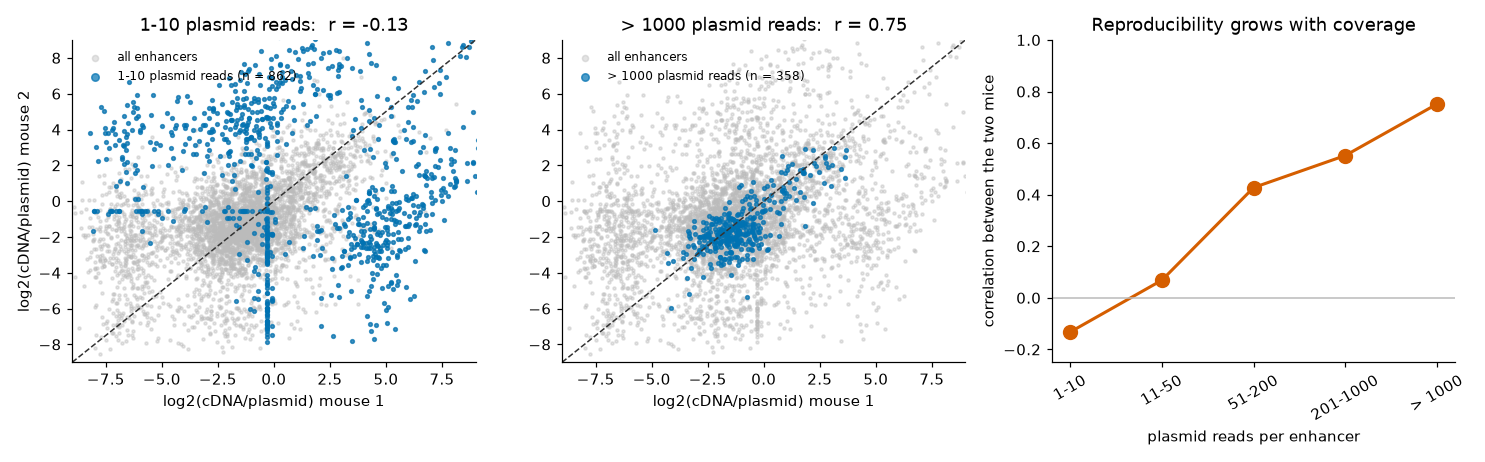

In [28]:
python - << 'EOF'
import pandas as pd, numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

BLUE, ORANGE, GREY = "#0072B2", "#D55E00", "#BBBBBB"
counts = pd.read_csv("counts/12K_5prime_counts.tsv", sep="\t", index_col=0)
cpm = counts / counts.sum() * 1e6

# crude activity estimate per mouse: log2 ratio of cDNA over plasmid
mouse1 = np.log2((cpm["mouse1_rep2_cDNA"] + 1) / (cpm["mouse1_rep2_plasmid"] + 1))
mouse2 = np.log2((cpm["mouse2_rep2_cDNA"] + 1) / (cpm["mouse2_rep2_plasmid"] + 1))
# how well is each enhancer covered? take the smallest plasmid count of the two mice
coverage = counts[["mouse1_rep2_plasmid", "mouse2_rep2_plasmid"]].min(axis=1)

df = pd.DataFrame({"mouse1": mouse1, "mouse2": mouse2, "coverage": coverage})
df = df[df.coverage > 0]
df["group"] = pd.cut(df.coverage, [0, 10, 50, 200, 1000, 1e9],
                     labels=["1-10", "11-50", "51-200", "201-1000", "> 1000"])
groups = df.groupby("group", observed=True)
summary = pd.DataFrame({
    "n": groups.size(),
    "r": groups.apply(lambda g: np.corrcoef(g.mouse1, g.mouse2)[0, 1], include_groups=False),
})
print(f"all {len(df)} enhancers with coverage > 0: r = {np.corrcoef(df.mouse1, df.mouse2)[0, 1]:.2f}")
print()
print(summary.round(2).to_string())

fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.2))
lim = (-9, 9)
for ax, grp in zip(axs[:2], ["1-10", "> 1000"]):
    sub = df[df.group == grp]
    ax.scatter(df.mouse1, df.mouse2, s=4, color=GREY, alpha=.4, label="all enhancers")
    ax.scatter(sub.mouse1, sub.mouse2, s=6, color=BLUE, alpha=.7,
               label=f"{grp} plasmid reads (n = {len(sub)})")
    ax.plot(lim, lim, color="#333333", lw=1, ls="--")
    ax.set(xlim=lim, ylim=lim, xlabel="log2(cDNA/plasmid) mouse 1",
           title=f"{grp} plasmid reads:  r = {summary.loc[grp, 'r']:.2f}")
    ax.legend(frameon=False, fontsize=8, loc="upper left", markerscale=2)
axs[0].set_ylabel("log2(cDNA/plasmid) mouse 2")

axs[2].plot(range(len(summary)), summary.r, "o-", color=ORANGE, lw=2, ms=9)
axs[2].set_xticks(range(len(summary)), summary.index, rotation=30)
axs[2].set(xlabel="plasmid reads per enhancer", ylabel="correlation between the two mice",
           ylim=(-0.25, 1), title="Reproducibility grows with coverage")
axs[2].axhline(0, color=GREY, lw=1)
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("counts/reproducibility.png", dpi=110)
EOF
display < counts/reproducibility.png

Two things to take away:

- The agreement between two mice is **poor for enhancers with few plasmid reads** and only becomes good for the best covered ones. An enhancer that is seen in 5 plasmid reads cannot be measured precisely, no matter how clever the analysis.
- Even overall, a single mouse gives a noisy measurement. This is why the authors injected several mice, and why in part 2 we will not work with these crude ratios but model all replicates together with DESeq2, which weighs each enhancer by how well it is measured and discards the ones with too few reads.

**Question**: Which of the two numbers do you think limits the precision most in this experiment: the number of *barcodes* per enhancer in the plasmid library (step 4e), or the number of *reads* per enhancer in the sequencing?

The more barcodes an enhancer has, the better the two mice agree on its RNA/DNA ratio. This is why MPRA libraries are cloned at a high complexity (the authors aimed for 500 barcodes per enhancer), and why it is a good idea to ignore enhancers with very few barcodes.

## What we have now

- A **dictionary** linking 7.5 million plasmid barcodes to the enhancer they belong to.
- A **count table** (`counts/12K_5prime_counts.tsv`) with the number of barcode reads per enhancer for 4 cDNA samples and their 4 matching plasmid samples.

The 3' library (and the 455 library of part 2) was processed in exactly the same way, with one difference: there, the enhancer-barcode assignment was made with **Oxford Nanopore** long reads. The barcode is at the other end of the plasmid, too far from the enhancer to be covered by a 51 bp Illumina read pair, but a single Nanopore read easily spans the whole insert. Those reads were mapped with `minimap2` to a synthetic genome containing the plasmid with every possible enhancer, and the enhancer and barcode were read out of the alignment.

In **part 2** we use the count tables of all experiments (ours and the ones from GEO) to calculate enhancer activities with DESeq2, decide which enhancers are active, and interpret the results.